# Start Here: PyTorch From Zero

> **Who is this for:** a complete beginner who has written a little Python and wants to understand how deep learning code *actually works*, line by line. You do **not** need to know any calculus beyond "slope of a line".
>
> **What you will learn:**
> - What a **tensor** is, and how it differs from a Python list and a NumPy array
> - How to create, reshape, index, broadcast and multiply tensors, and how to read a shape error
> - How PyTorch computes slopes for you automatically (**autograd**)
> - How to train a model three ways: by hand, with `nn.Linear` + an optimizer, and with mini-batches from a `DataLoader`
> - How to build your first real neural network with `nn.Module`, check it on validation data, see it overfit, and fix it
> - Classification losses, softmax, `model.train()` vs `model.eval()`, and saving / loading a model
> - A practical checklist for debugging a training loop that does not work
>
> **Prerequisites:** basic Python ([01_Python/01_basic.ipynb](../01_Python/01_basic.ipynb)); it helps (but is not required) to have seen NumPy and a simple model such as [linear regression](../03_Machine_Learning/01_supervised/01_linear_regression.ipynb). Optional math background: [vectors and matrices](../14_Mathematics/01_linear_algebra.ipynb) and [derivatives](../14_Mathematics/02_calculus.ipynb).
>
> **Time needed:** about 2-3 hours if you read every cell and try the exercises.
>
> **Runs on:** CPU, no API key, no internet, no downloads. The whole notebook runs in about one to two minutes.

## How this notebook is organised

| Part | Topic | The one question it answers |
|---|---|---|
| 1 | Tensors | "How does PyTorch store numbers?" |
| 2 | Autograd | "How does PyTorch know which way to nudge the numbers?" |
| 3 | Linear regression, 3 ways | "What does a training loop look like?" |
| 4 | Your first neural network | "How do I learn a curved (non-linear) pattern, and how do I know it works?" |
| 5 | Classification details | "Logits, softmax, train/eval mode, saving a model" |
| 6 | Debugging checklist | "My loss is not going down. Now what?" |

A tiny vocabulary list before we start (each word is explained again when it first appears in code):

| Word | Plain-English meaning |
|---|---|
| **Model** | A function with adjustable knobs that turns inputs into predictions |
| **Parameter** (or **weight**) | One of those adjustable knobs (just a number) |
| **Loss** | One number that says how wrong the predictions are (smaller = better) |
| **Gradient** | For every knob: "if I turn this knob up a tiny bit, does the loss go up or down, and how fast?" |
| **Training** | Repeatedly nudging every knob a little in the direction that makes the loss smaller |

## Setup

We import the libraries and **seed** the random number generators. A **seed** is a starting point for the random number generator: with the same seed you get the same "random" numbers every run, so your results match the ones described in this notebook.

In [1]:
import time                                   # to time things
import tempfile, shutil, os                   # temporary folders for saving a model
import warnings                               # to catch a warning on purpose later

import numpy as np                            # classic array library
import matplotlib.pyplot as plt               # plotting
import torch                                  # PyTorch itself
import torch.nn as nn                         # building blocks for neural networks
import torch.nn.functional as F               # functions such as softmax / relu
from torch.utils.data import TensorDataset, DataLoader   # mini-batch helpers
from sklearn.datasets import make_moons       # a small toy dataset (no download)
from sklearn.model_selection import train_test_split     # split data into train / validation

SEED = 42                                     # any fixed number works
np.random.seed(SEED)                          # seed NumPy
torch.manual_seed(SEED)                       # seed PyTorch
torch.set_num_threads(2)                      # tiny models run fastest on a couple of CPU threads
NOTEBOOK_START = time.time()                  # remember when we started

print("PyTorch version:", torch.__version__)
print("NumPy version:  ", np.__version__)

PyTorch version: 2.12.1+cpu
NumPy version:   2.4.6


**What just happened?**

We loaded PyTorch (`torch`) plus a few helpers. The exact version numbers on your machine may differ from the ones printed here; everything in this notebook works with any PyTorch 2.x release.

---
# Part 1: Tensors

## 1.1 What is a tensor?

A **tensor** is a box of numbers arranged in a grid with any number of directions (**dimensions**, also called **axes**). You already know the first few:

| Name | Dimensions | Example | Shape example |
|---|---|---|---|
| **Scalar** | 0 | one temperature: `21.5` | `()` |
| **Vector** | 1 | temperatures for a week | `(7,)` |
| **Matrix** | 2 | a spreadsheet: 100 rows (houses) x 3 columns (features) | `(100, 3)` |
| **3-D tensor** | 3 | one colour photo: 3 colour channels x 32 rows x 32 columns | `(3, 32, 32)` |
| **4-D tensor** | 4 | a *batch* of 64 colour photos | `(64, 3, 32, 32)` |

The **shape** is the list of sizes along each dimension. Most deep learning bugs are shape bugs, so you will print `.shape` constantly.

**Why not just use a Python list or a NumPy array?** Let's compare all three.

In [2]:
py_list = [1.0, 2.0, 3.0]                  # a plain Python list
np_arr  = np.array([1.0, 2.0, 3.0])        # a NumPy array
t       = torch.tensor([1.0, 2.0, 3.0])    # a PyTorch tensor

print("list   * 2 ->", py_list * 2)        # lists REPEAT, they do not do math
print("NumPy  * 2 ->", np_arr * 2)         # arrays multiply every element
print("tensor * 2 ->", t * 2)              # tensors also multiply every element
print()
print("type of each:", type(py_list).__name__, "|", type(np_arr).__name__, "|", type(t).__name__)

list   * 2 -> [1.0, 2.0, 3.0, 1.0, 2.0, 3.0]
NumPy  * 2 -> [2. 4. 6.]
tensor * 2 -> tensor([2., 4., 6.])

type of each: list | ndarray | Tensor


**What just happened?**

- Multiplying a **list** by 2 *repeats* it (`[1, 2, 3, 1, 2, 3]`). Lists are general containers, not math objects.
- A **NumPy array** and a **tensor** both do element-by-element math. They look almost identical.

So what does a tensor add on top of NumPy? Two superpowers:

| Feature | Python list | NumPy array | PyTorch tensor |
|---|---|---|---|
| Fast element-wise math | No | Yes | Yes |
| Runs on a **GPU** (graphics card) | No | No | Yes |
| Computes gradients automatically (**autograd**, Part 2) | No | No | Yes |

Those two extra features are exactly what deep learning needs.

## 1.2 Creating tensors, `dtype` and `shape`

Every tensor has a **dtype** (data type: what kind of number is stored in each cell) and a **shape**.

In [3]:
a = torch.tensor([[1, 2, 3],
                  [4, 5, 6]])               # built from a nested list (2 rows, 3 columns)
b = torch.zeros(2, 3)                       # 2x3 of zeros
c = torch.ones(3)                           # vector of three 1s
d = torch.arange(0, 10, 2)                  # 0, 2, 4, 6, 8 (like Python's range)
e = torch.rand(2, 2)                        # uniform random numbers in [0, 1)
f = torch.randn(2, 2)                       # random numbers from a bell curve (mean 0, std 1)

for name, x in [("a", a), ("b", b), ("c", c), ("d", d), ("e", e), ("f", f)]:
    print(f"{name}: shape={tuple(x.shape)!s:8} dtype={x.dtype}")
print()
print("a =\n", a)

a: shape=(2, 3)   dtype=torch.int64
b: shape=(2, 3)   dtype=torch.float32
c: shape=(3,)     dtype=torch.float32
d: shape=(5,)     dtype=torch.int64
e: shape=(2, 2)   dtype=torch.float32
f: shape=(2, 2)   dtype=torch.float32

a =
 tensor([[1, 2, 3],
        [4, 5, 6]])


**What just happened?**

- `a` was made from whole numbers, so PyTorch picked **`torch.int64`** (64-bit integers).
- Everything else holds decimals, so the dtype is **`torch.float32`** (32-bit floating point). This is the default for neural networks: it is precise enough and twice as compact as NumPy's default `float64`.
- `shape` tells us `a` has 2 rows and 3 columns.

> ⚠️ **Common mistake: integer tensors going into a neural network.**
> Layers such as `nn.Linear` store `float32` weights. Feeding them an `int64` tensor raises an error like `mat1 and mat2 must have the same dtype`. Fix it with `.float()`. Let's see the conversion:

In [4]:
a_float = a.float()                         # convert int64 -> float32
print(a.dtype, "->", a_float.dtype)
print(a_float)

t64 = torch.tensor([1.5, 2.5], dtype=torch.float64)   # you can also choose the dtype up front
print("explicit dtype:", t64.dtype)

torch.int64 -> torch.float32
tensor([[1., 2., 3.],
        [4., 5., 6.]])
explicit dtype: torch.float64


**What just happened?**

`.float()` makes a float32 copy. You can also pass `dtype=` when creating a tensor. Rule of thumb: **inputs and weights are `float32`; class labels for classification are `int64` (also called `long`)**. You will see why in Part 5.

## 1.3 Reshaping: `reshape` and `view`

**Reshaping** rearranges the same numbers into a different grid, like pouring 12 eggs from a 2x6 carton into a 3x4 carton. The total count must stay the same.

You can write `-1` for one dimension and PyTorch will work it out ("whatever size makes it fit").

In [5]:
x = torch.arange(12)                        # 0..11, shape (12,)
print("original     :", tuple(x.shape))

r1 = x.reshape(3, 4)                        # 3 rows x 4 columns
r2 = x.reshape(2, -1)                       # 2 rows, PyTorch computes 6 columns
r3 = x.view(4, 3)                           # view = reshape that never copies memory
r4 = x.reshape(2, 2, 3)                     # a 3-D tensor
print("reshape(3,4)  :", tuple(r1.shape))
print("reshape(2,-1) :", tuple(r2.shape))
print("view(4,3)     :", tuple(r3.shape))
print("reshape(2,2,3):", tuple(r4.shape))
print(r1)

flat = r1.flatten()                         # back to one long vector
print("flatten       :", tuple(flat.shape))

original     : (12,)
reshape(3,4)  : (3, 4)
reshape(2,-1) : (2, 6)
view(4,3)     : (4, 3)
reshape(2,2,3): (2, 2, 3)
tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])
flatten       : (12,)


**What just happened?**

The 12 numbers never changed; only the way we *group* them did. `view` and `reshape` usually behave identically; `view` refuses to work if the data would need copying, while `reshape` copies when it must. **Beginners can just use `reshape`.**

`flatten()` turns any shape back into one long vector. Two relatives you will meet in Part 6: `unsqueeze(dim)` adds a size-1 dimension and `squeeze(dim)` removes one.

## 1.4 Indexing and slicing

Indexing works like NumPy: `t[row, column]`, with `:` meaning "all" and slices `start:stop` (stop not included).

In [6]:
m = torch.arange(1, 13).reshape(3, 4)       # numbers 1..12 in 3 rows, 4 columns
print(m)
print("m[0, 0]   =", m[0, 0].item())        # .item() turns a 1-element tensor into a Python number
print("m[1]      =", m[1])                  # whole second row
print("m[:, 2]   =", m[:, 2])               # whole third column
print("m[0:2, 1:3] =\n", m[0:2, 1:3])       # a 2x2 sub-block
print("m[m > 6]  =", m[m > 6])              # boolean mask: keep values greater than 6

tensor([[ 1,  2,  3,  4],
        [ 5,  6,  7,  8],
        [ 9, 10, 11, 12]])
m[0, 0]   = 1
m[1]      = tensor([5, 6, 7, 8])
m[:, 2]   = tensor([ 3,  7, 11])
m[0:2, 1:3] =
 tensor([[2, 3],
        [6, 7]])
m[m > 6]  = tensor([ 7,  8,  9, 10, 11, 12])


**What just happened?**

- Counting starts at **0**, so `m[1]` is the *second* row.
- `.item()` converts a single-number tensor into a normal Python number (handy for printing losses).
- `m > 6` creates a tensor of `True`/`False`; using it as an index keeps only the `True` positions. This is called a **boolean mask**.

## 1.5 Element-wise math and broadcasting

Arithmetic (`+ - * /`) between tensors of the same shape happens **element by element**.

**Broadcasting** is PyTorch's rule for combining tensors of *different* shapes: a dimension of size 1 (or a missing dimension) is "stretched" to match the other tensor, without actually copying data.

```
 matrix (2, 3)          row (3,)              result (2, 3)
 [[1, 2, 3],     +     [10, 20, 30]    =     [[11, 22, 33],
  [4, 5, 6]]           (stretched to          [14, 25, 36]]
                        both rows)
```

Two shapes are compatible if, comparing from the **right**, each pair of sizes is equal or one of them is 1.

In [7]:
mat = torch.tensor([[1., 2., 3.],
                    [4., 5., 6.]])          # shape (2, 3)
row = torch.tensor([10., 20., 30.])         # shape (3,)   -> stretched over the 2 rows
col = torch.tensor([[100.], [200.]])        # shape (2, 1) -> stretched over the 3 columns

print("mat * mat (element-wise):\n", mat * mat)
print("mat + row:\n", mat + row)
print("mat + col:\n", mat + col)
print("mat - mat.mean(dim=0)  (centre each column):\n", mat - mat.mean(dim=0))

mat * mat (element-wise):
 tensor([[ 1.,  4.,  9.],
        [16., 25., 36.]])
mat + row:
 tensor([[11., 22., 33.],
        [14., 25., 36.]])
mat + col:
 tensor([[101., 102., 103.],
        [204., 205., 206.]])
mat - mat.mean(dim=0)  (centre each column):
 tensor([[-1.5000, -1.5000, -1.5000],
        [ 1.5000,  1.5000,  1.5000]])


**What just happened?**

- `mat * mat` squares each element; it is **not** matrix multiplication.
- `row` (3 numbers) was added to *each* row; `col` (2 numbers) was added to *each* column.
- `mat.mean(dim=0)` averages down the rows (one mean per column, shape `(3,)`), and broadcasting subtracts it from every row. This "centre each column" trick is how data is normalised.

## 1.6 Matrix multiplication

**Matrix multiplication** (`@` or `torch.matmul`) is the core operation of every neural network layer. The shape rule:

```
   (n, k)  @  (k, m)   ->   (n, m)
        \______/
   inner sizes must match
```

Think of it as: *n* data rows, each with *k* features, multiplied by a weight matrix that turns *k* features into *m* outputs.

In [8]:
X = torch.randn(5, 3)                       # 5 samples, 3 features each
W = torch.randn(3, 2)                       # weights: 3 inputs -> 2 outputs
out = X @ W                                 # matrix multiplication
print("X:", tuple(X.shape), " W:", tuple(W.shape), " ->  X @ W:", tuple(out.shape))

v = torch.tensor([1., 2., 3.])
w = torch.tensor([4., 5., 6.])
print("dot product v @ w =", (v @ w).item(), "  (1*4 + 2*5 + 3*6 = 32)")

X: (5, 3)  W: (3, 2)  ->  X @ W: (5, 2)
dot product v @ w = 32.0   (1*4 + 2*5 + 3*6 = 32)


**What just happened?**

5 samples with 3 features went in; 5 samples with 2 outputs came out. The inner 3s "cancelled". For two vectors, `@` gives the **dot product**: multiply matching elements and add them up (here 32).

## 1.7 A deliberate shape error (and how to read it)

Errors are your friends: they tell you exactly what went wrong. Let's multiply two matrices whose inner sizes do **not** match, and catch the error so the notebook keeps running.

In [9]:
A = torch.randn(4, 3)                       # 4 x 3
B = torch.randn(4, 2)                       # 4 x 2  (wrong! inner sizes 3 and 4 differ)
try:
    A @ B
except RuntimeError as err:                 # catch the error instead of crashing
    print("RuntimeError:", err)

print("Fix 1: transpose A ->", tuple((A.T @ B).shape))   # (3,4) @ (4,2) -> (3,2)

RuntimeError: mat1 and mat2 shapes cannot be multiplied (4x3 and 4x2)
Fix 1: transpose A -> (3, 2)


**What just happened?**

The message reads `mat1 and mat2 shapes cannot be multiplied (4x3 and 4x2)`. Read it like this:

1. **mat1** is the left matrix (`A`, 4x3), **mat2** is the right one (`B`, 4x2).
2. For `@` the *last* size of mat1 (3) must equal the *first* size of mat2 (4). They don't.
3. Decide which tensor has the wrong layout. Here, transposing `A` (`A.T`, swapping rows and columns) makes the inner sizes match.

> 💡 **Tip:** when you get a shape error, print the `.shape` of every tensor on that line *before* changing any code.

## 1.8 NumPy ⇄ PyTorch

You will constantly move data between NumPy (pandas, scikit-learn, matplotlib all speak NumPy) and PyTorch.

| Direction | Code | Shares memory? |
|---|---|---|
| NumPy → tensor | `torch.from_numpy(arr)` | **Yes** (changing one changes the other) |
| NumPy → tensor | `torch.tensor(arr)` | No (a copy) |
| tensor → NumPy | `t.numpy()` | **Yes** (CPU tensors only) |
| tensor → NumPy, when it needs gradients | `t.detach().cpu().numpy()` | No |

In [10]:
arr = np.array([1.0, 2.0, 3.0])             # NumPy float64 array
shared = torch.from_numpy(arr)              # shares memory with arr
copied = torch.tensor(arr)                  # independent copy

arr[0] = 999.0                              # change the NumPy array
print("shared:", shared)                    # sees the change!
print("copied:", copied)                    # does not
print("dtype after conversion:", shared.dtype)   # float64 comes along from NumPy

back = copied.numpy()                       # tensor -> NumPy
print("back to NumPy:", back, type(back).__name__)

shared: tensor([999.,   2.,   3.], dtype=torch.float64)
copied: 

tensor([1., 2., 3.], dtype=torch.float64)
dtype after conversion: torch.float64
back to NumPy: [1. 2. 3.] ndarray


**What just happened?**

- `torch.from_numpy` is fast because it does not copy, but that also means edits leak between the two. `torch.tensor(...)` makes a safe copy.
- NumPy's default dtype is `float64`, and it comes along. Neural network layers want `float32`, so you usually write `torch.tensor(arr, dtype=torch.float32)`.

## 1.9 Choosing a device: CPU, GPU (CUDA) or Apple GPU (MPS)

A **device** is where a tensor lives and where its math runs. Tensors that interact must be on the **same** device. This is the standard pattern, which works on any machine:

In [11]:
if torch.cuda.is_available():                   # NVIDIA graphics card
    device = torch.device("cuda")
elif torch.backends.mps.is_available():         # Apple Silicon (M1/M2/...) graphics
    device = torch.device("mps")
else:                                           # plain processor: always available
    device = torch.device("cpu")
print("Using device:", device)

t_dev = torch.ones(3).to(device)                # move a tensor to the chosen device
print("tensor lives on:", t_dev.device)

Using device:

 cpu
tensor lives on: cpu


**What just happened?**

This notebook is designed for the **CPU**, so on most laptops it prints `cpu`. If you have a GPU, the same code moves tensors there with `.to(device)`; the model also needs `model.to(device)`. Everything below is small enough that the CPU is fast.

> ⚠️ **Common mistake:** `Expected all tensors to be on the same device` means you moved the model but not the data (or the other way round). Move *both* with `.to(device)`.

---
# Part 2: Autograd, gradients from zero

## 2.1 The idea

Training means: change each knob (parameter) in the direction that reduces the loss. To know the direction we need the **gradient**: the slope of the loss with respect to each knob.

- Slope **positive** → increasing the knob increases the loss → turn it **down**.
- Slope **negative** → turn it **up**.

Computing slopes by hand for millions of knobs is impossible. **Autograd** ("automatic gradient") does it for you:

1. Mark a tensor with `requires_grad=True` ("please track what I do with this").
2. Do your math. PyTorch silently records every step in a **computation graph**.
3. Call `.backward()` on the final single number. PyTorch walks the graph backwards and fills in `.grad` for every tracked tensor.

In [12]:
x = torch.tensor(2.0, requires_grad=True)   # a tracked number, x = 2
y = x**2 + 3*x                              # y = x^2 + 3x  -> at x=2: 4 + 6 = 10
print("y =", y.item())
print("y.grad_fn =", y.grad_fn)             # the recorded last step of the computation

y.backward()                                # compute dy/dx and store it in x.grad
print("autograd slope dy/dx =", x.grad.item())

hand = 2*2.0 + 3                            # by hand: d(x^2 + 3x)/dx = 2x + 3 = 7 at x = 2
print("hand-calculated slope =", hand)

y = 10.0
y.grad_fn = <AddBackward0 object at 0x7a8275b473a0>


autograd slope dy/dx = 7.0
hand-calculated slope = 7.0


**What just happened?**

- `y` has a `grad_fn`: proof that PyTorch remembered how `y` was made.
- `y.backward()` filled `x.grad` with **7.0**, exactly what the school rule gives: the slope of `x² + 3x` is `2x + 3`, which is `7` at `x = 2`.

**What the slope means:** if we increase `x` from 2 to 2.001, `y` grows by about `7 × 0.001 = 0.007`. Let's check that numerically too, without autograd:

In [13]:
def f(v):                                   # the same function, plain Python
    return v**2 + 3*v

h = 1e-4                                    # a tiny nudge
numeric = (f(2.0 + h) - f(2.0 - h)) / (2*h) # slope = rise / run around x = 2
print(f"numeric slope ~ {numeric:.4f}")

numeric slope ~ 7.0000


**What just happened?**

Nudging `x` a tiny bit and measuring how much `f` changes gives the same slope (7). Autograd gives this *exactly* and for every parameter at once, in a single backward pass.

## 2.2 A tiny model: one prediction, one loss

Now something closer to real training. A model `prediction = w * x + b` with two knobs `w` and `b`, one data point `x = 3`, true answer `y = 10`, and a **squared error** loss: `(prediction - y)²`.

Hand calculation (chain rule, the "slope of a slope" rule):

| Quantity | Formula | Value with w=1, b=0 |
|---|---|---|
| prediction | `w*x + b` | `3` |
| error | `prediction - y` | `-7` |
| loss | `error²` | `49` |
| slope w.r.t. `w` | `2 * error * x` | `2 * -7 * 3 = -42` |
| slope w.r.t. `b` | `2 * error * 1` | `2 * -7 = -14` |

In [14]:
w = torch.tensor(1.0, requires_grad=True)   # knob 1
b = torch.tensor(0.0, requires_grad=True)   # knob 2
x_pt, y_true = torch.tensor(3.0), torch.tensor(10.0)   # data: no gradient needed

pred = w * x_pt + b                         # forward pass: make a prediction
loss = (pred - y_true) ** 2                 # how wrong are we?
loss.backward()                             # backward pass: fill w.grad and b.grad

print(f"prediction={pred.item()}, loss={loss.item()}")
print(f"w.grad = {w.grad.item()}   (hand: -42)")
print(f"b.grad = {b.grad.item()}   (hand: -14)")

prediction=3.0, loss=49.0
w.grad = -42.0   (hand: -42)
b.grad = -14.0   (hand: -14)


**What just happened?**

Autograd matches the hand calculation exactly: `w.grad = -42`, `b.grad = -14`. Both slopes are **negative**, meaning "increase `w` and `b` to reduce the loss", which makes sense because our prediction (3) is far below the target (10).

## 2.3 Why we must call `zero_grad`: gradients accumulate

PyTorch **adds** new gradients to whatever is already stored in `.grad`. It does not overwrite. Watch what happens if we run backward three times without clearing:

In [15]:
w = torch.tensor(1.0, requires_grad=True)
for step in range(1, 4):
    loss = (w * 3.0 - 10.0) ** 2            # same loss as before (b left out)
    loss.backward()                         # ADDS to w.grad
    print(f"after backward #{step}: w.grad = {w.grad.item()}")

w.grad.zero_()                              # clear it (what optimizer.zero_grad() does for you)
print("after zero_():", w.grad.item())

after backward #1: w.grad = -42.0
after backward #2: w.grad = -84.0
after backward #3: w.grad = -126.0
after zero_(): 0.0


**What just happened?**

The true slope is -42 every time, but the stored gradient grew to -84 and then -126: it **accumulated**. If you forget to clear it in a training loop, each step uses the sum of all previous gradients, and training goes haywire (we demonstrate this in Part 6).

Why does PyTorch accumulate at all? It is useful on purpose sometimes (for example, adding up gradients from several small batches when one big batch does not fit in memory). But in a normal loop you **clear gradients every step**, using `optimizer.zero_grad()`.

## 2.4 `torch.no_grad()`: switching tracking off

Recording the computation graph costs memory and time. When you only want predictions (**inference**) or when you update weights by hand, wrap the code in `with torch.no_grad():`.

In [16]:
w = torch.tensor(1.0, requires_grad=True)
y1 = w * 3                                  # tracked
with torch.no_grad():                       # nothing inside is tracked
    y2 = w * 3
print("y1.requires_grad:", y1.requires_grad, "| y2.requires_grad:", y2.requires_grad)

d = y1.detach()                             # another way: a copy cut off from the graph
print("detached requires_grad:", d.requires_grad)

y1.requires_grad: True | y2.requires_grad: False
detached requires_grad: False


**What just happened?**

Inside `torch.no_grad()` the result `y2` is a plain number with no history. `.detach()` does the same for one tensor; you need it before converting a tracked tensor to NumPy (`t.detach().numpy()`).

---
# Part 3: Linear regression, trained three ways

**Linear regression** fits a straight line `y = w*x + b` through points. We make fake data where we *know* the true answer (`w = 3`, `b = 2`) so we can check whether training finds it.

We will train the same model three ways, each one closer to how professionals write it:

| Way | What we write ourselves | What PyTorch does |
|---|---|---|
| (a) Manual | the model, the loss, the update rule | only the gradients |
| (b) `nn.Linear` + `optim.SGD` | the loop | model, loss, update |
| (c) `DataLoader` | the loop over mini-batches | also shuffling and batching |

X shape: (100, 1)  Y shape: (100, 1)


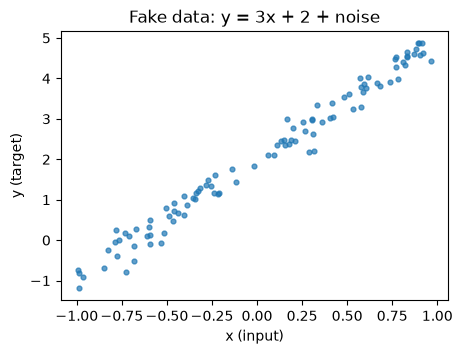

In [17]:
torch.manual_seed(SEED)
N = 100                                     # number of data points
X = torch.rand(N, 1) * 2 - 1                # inputs between -1 and 1, shape (100, 1)
noise = torch.randn(N, 1) * 0.3             # random noise so the points are not perfect
Y = 3 * X + 2 + noise                       # true rule: y = 3x + 2 (+ noise)
print("X shape:", tuple(X.shape), " Y shape:", tuple(Y.shape))

plt.figure(figsize=(5, 3.5))
plt.scatter(X, Y, s=12, alpha=0.7)
plt.xlabel("x (input)"); plt.ylabel("y (target)")
plt.title("Fake data: y = 3x + 2 + noise")
plt.show()

**What just happened?**

100 points scattered around a straight line. Notice the shape `(100, 1)`: **100 rows (samples), 1 column (feature)**. PyTorch layers always expect the first dimension to be the **batch** (the samples).

## 3a. Manual gradient descent with autograd

**Gradient descent** = repeat many times:
1. predict, 2. measure the loss, 3. compute gradients, 4. move each knob a small step *against* its gradient, 5. clear the gradients.

The step size is the **learning rate** (`lr`): too small and training crawls; too large and it overshoots (Part 6). The loss here is the **mean squared error (MSE)**: the average of `(prediction - target)²`.

In [18]:
torch.manual_seed(SEED)
w = torch.randn(1, requires_grad=True)       # random starting knobs
b = torch.zeros(1, requires_grad=True)
lr = 0.1                                     # learning rate
losses_a = []                                # remember the loss at every step

for epoch in range(200):                     # an epoch = one pass over all data
    pred = X * w + b                         # 1. forward: predictions for all 100 points
    loss = ((pred - Y) ** 2).mean()          # 2. MSE loss
    loss.backward()                          # 3. gradients -> w.grad, b.grad
    with torch.no_grad():                    # 4. update WITHOUT recording it in the graph
        w -= lr * w.grad
        b -= lr * b.grad
    w.grad.zero_(); b.grad.zero_()           # 5. clear gradients for the next step
    losses_a.append(loss.item())

print(f"learned w = {w.item():.3f}, b = {b.item():.3f}   (truth: 3, 2)")
print(f"loss: first = {losses_a[0]:.3f}, last = {losses_a[-1]:.4f}")

learned w = 2.931, b = 2.000   (truth: 3, 2)
loss: first = 6.707, last = 0.0597


**What just happened?**

Starting from a random `w` and `b = 0`, 200 small steps brought the knobs close to the true values 3 and 2 (you should see roughly `w ≈ 2.93`, `b ≈ 2.00`; not exact, because of the noise we added). The loss fell from about 6.7 to about 0.06. That is the **noise level**: we added noise with a spread of 0.3 (so a squared size of roughly `0.3² = 0.09`; this particular sample happens to come out a bit smaller), and no straight line can predict random noise. So this is as good as it gets.

Every training loop you will ever see is a dressed-up version of these five lines.

## 3b. The same thing with `nn.Linear` and `optim.SGD`

PyTorch has ready-made pieces:

| Piece | Replaces |
|---|---|
| `nn.Linear(1, 1)` | our `w` and `b` (it creates and stores them) |
| `nn.MSELoss()` | our `((pred - Y)**2).mean()` |
| `optim.SGD(model.parameters(), lr=0.1)` | our manual update and manual zeroing |

**SGD** stands for **stochastic gradient descent**: gradient descent, usually on random subsets of the data.

In [19]:
torch.manual_seed(SEED)
model_b = nn.Linear(in_features=1, out_features=1)          # y = w*x + b, knobs created for us
loss_fn = nn.MSELoss()                                       # mean squared error
optimizer = torch.optim.SGD(model_b.parameters(), lr=0.1)   # knows which knobs to update
losses_b = []

for epoch in range(200):
    pred = model_b(X)                # forward
    loss = loss_fn(pred, Y)          # loss
    optimizer.zero_grad()            # clear old gradients
    loss.backward()                  # new gradients
    optimizer.step()                 # update every parameter: p -= lr * p.grad
    losses_b.append(loss.item())

print(f"learned w = {model_b.weight.item():.3f}, b = {model_b.bias.item():.3f}")
print(f"final loss = {losses_b[-1]:.4f}")

learned w = 2.931, b = 2.000
final loss = 0.0597


**What just happened?**

Same result, less code, and fewer places to make a mistake. The knobs now live inside the model as `model_b.weight` and `model_b.bias`. `optimizer.step()` performs exactly our manual update `p -= lr * p.grad` for every parameter.

## 3c. Mini-batches with `TensorDataset` and `DataLoader`

Real datasets are too big to push through the model all at once. Instead we use **mini-batches**: small random groups of samples (here 16). One **epoch** is one full pass over all the data, which now takes several steps.

- `TensorDataset(X, Y)` pairs each input with its target.
- `DataLoader(..., batch_size=16, shuffle=True)` hands out shuffled batches of 16.

In [20]:
torch.manual_seed(SEED)
dataset = TensorDataset(X, Y)                                # (x_i, y_i) pairs
loader = DataLoader(dataset, batch_size=16, shuffle=True)    # shuffled batches of 16
xb, yb = next(iter(loader))                                  # peek at one batch
print("one batch:", tuple(xb.shape), tuple(yb.shape), "| batches per epoch:", len(loader))

model_c = nn.Linear(1, 1)
optimizer = torch.optim.SGD(model_c.parameters(), lr=0.1)
losses_c = []                                                # one value per epoch
for epoch in range(30):                                      # fewer epochs: many steps each
    epoch_loss = 0.0
    for xb, yb in loader:                                    # loop over mini-batches
        loss = loss_fn(model_c(xb), yb)                      # forward + loss
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        epoch_loss += loss.item() * len(xb)                  # sum of per-sample losses
    losses_c.append(epoch_loss / len(dataset))               # average loss this epoch
print(f"learned w = {model_c.weight.item():.3f}, b = {model_c.bias.item():.3f}")
print(f"final epoch loss = {losses_c[-1]:.4f}")

one batch: (16, 1) (16, 1) | batches per epoch: 7


learned w = 2.939, b = 1.965
final epoch loss = 0.0607


**What just happened?**

- 100 samples in batches of 16 gives **7 batches per epoch** (the last one has only 4 samples).
- Because each epoch now contains 7 updates, 30 epochs (210 updates) is about as much work as the 200 full-data steps before, and we reach the same answer.
- With mini-batches each gradient is computed on a different random group, so the path to the answer is slightly noisy. That noise is the "stochastic" in SGD, and it is normal.

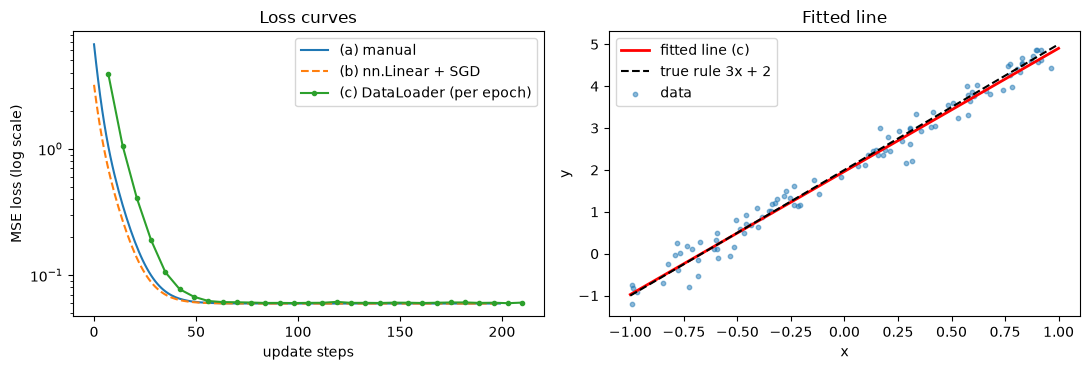

way                          w       b
(a) manual               2.931   2.000
(b) nn.Linear+SGD        2.931   2.000
(c) DataLoader           2.939   1.965


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(losses_a, label="(a) manual")                    # one value per step
axes[0].plot(losses_b, "--", label="(b) nn.Linear + SGD")
axes[0].plot(np.arange(1, 31) * len(loader), losses_c, "o-", ms=3, label="(c) DataLoader (per epoch)")
axes[0].set_yscale("log")                                     # log scale shows small values clearly
axes[0].set_xlabel("update steps"); axes[0].set_ylabel("MSE loss (log scale)")
axes[0].set_title("Loss curves"); axes[0].legend()

grid = torch.linspace(-1, 1, 50).reshape(-1, 1)               # x values for drawing the line
with torch.no_grad():                                         # inference: no tracking
    axes[1].plot(grid, model_c(grid), "r", lw=2, label="fitted line (c)")
axes[1].plot(grid, 3 * grid + 2, "k--", label="true rule 3x + 2")
axes[1].scatter(X, Y, s=10, alpha=0.5, label="data")
axes[1].set_xlabel("x"); axes[1].set_ylabel("y"); axes[1].set_title("Fitted line"); axes[1].legend()
plt.tight_layout(); plt.show()

print(f"{'way':<22}{'w':>8}{'b':>8}")
for name, (wv, bv) in {"(a) manual": (w.item(), b.item()),
                       "(b) nn.Linear+SGD": (model_b.weight.item(), model_b.bias.item()),
                       "(c) DataLoader": (model_c.weight.item(), model_c.bias.item())}.items():
    print(f"{name:<22}{wv:>8.3f}{bv:>8.3f}")

**What just happened?**

- **Left:** (a) and (b) follow the same rule, but start from different random knobs (we drew `w` with `torch.randn`, while `nn.Linear` uses its own random start), so their first steps differ slightly. Both settle at the same loss and, as the table shows, the same `w` and `b`. (c) is plotted once per epoch at "epoch × 7 update steps", so all three share the same x-axis, and it reaches the same low loss level.
- **Right:** the fitted red line sits almost on top of the true dashed line.
- **Table:** all three ways learn practically the same `w ≈ 3` and `b ≈ 2`.

> ⚠️ **Common mistake:** reusing short names like `w` and `b` across a notebook. Here the table is correct because 3a re-created `w` and `b` just before training, but if you run cells out of order a name can point to an older tensor. When in doubt, restart the kernel and run all cells top to bottom.

---
# Part 4: Your first neural network

## 4.1 A problem a straight line cannot solve

`make_moons` (from scikit-learn, no download) creates two interlocking half-moons. The task: given a point's 2 coordinates, predict which moon (class 0 or 1) it belongs to. This is **classification**.

We split the data into a **training set** (the model learns from it) and a **validation set** (kept aside to check how well the model does on points it has *never seen*). Validation accuracy is the honest score.

train: (450, 2)  validation: (150, 2)
labels look like: [0, 0, 0, 0, 1, 0, 1, 1, 0, 1]


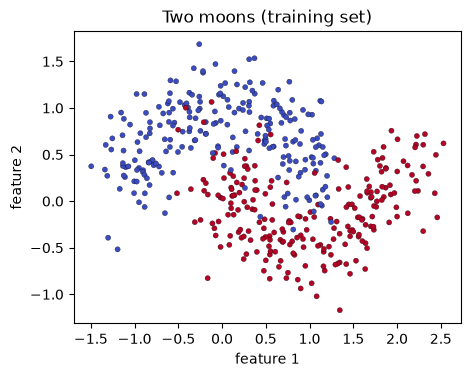

In [22]:
Xm, ym = make_moons(n_samples=600, noise=0.25, random_state=SEED)       # NumPy arrays
X_tr, X_va, y_tr, y_va = train_test_split(Xm, ym, test_size=0.25,
                                          random_state=SEED, stratify=ym)
X_tr = torch.tensor(X_tr, dtype=torch.float32)          # inputs: float32
X_va = torch.tensor(X_va, dtype=torch.float32)
y_tr = torch.tensor(y_tr, dtype=torch.long)             # class labels: int64 ("long")
y_va = torch.tensor(y_va, dtype=torch.long)
print("train:", tuple(X_tr.shape), " validation:", tuple(X_va.shape))
print("labels look like:", y_tr[:10].tolist())

plt.figure(figsize=(5, 3.8))
plt.scatter(X_tr[:, 0], X_tr[:, 1], c=y_tr, cmap="coolwarm", s=14, edgecolors="k", linewidths=0.2)
plt.xlabel("feature 1"); plt.ylabel("feature 2"); plt.title("Two moons (training set)")
plt.show()

**What just happened?**

450 training points and 150 validation points, each with 2 features. The labels are 0 (blue) and 1 (red). No straight line can separate the two moons perfectly; we need a model that can draw a **curved** boundary.

## 4.2 Defining a network with `nn.Module`

A neural network is layers of `nn.Linear` with a **non-linear activation function** in between. We use **ReLU** (rectified linear unit): `relu(z) = max(0, z)`, i.e. "keep positives, turn negatives into 0". Without it, stacking linear layers would still give just one straight line; ReLU is what lets the network bend.

```
 input (2) --Linear--> 16 --ReLU--> 16 --Linear--> 16 --ReLU--> 16 --Linear--> 2 scores
                       "hidden layer 1"           "hidden layer 2"             (one per class)
```

The 2 outputs are raw scores called **logits**, one per class. The bigger score wins. (We turn them into probabilities in Part 5.)

In PyTorch you write a class that inherits from `nn.Module` with two parts:
- `__init__`: create the layers (the knobs live here),
- `forward`: describe how data flows through them.

In [23]:
class MoonNet(nn.Module):
    def __init__(self, hidden=16):
        super().__init__()                           # required first line
        self.layer1 = nn.Linear(2, hidden)           # 2 features -> hidden units
        self.layer2 = nn.Linear(hidden, hidden)      # hidden -> hidden
        self.out = nn.Linear(hidden, 2)              # hidden -> 2 class scores (logits)

    def forward(self, x):                            # called when you write model(x)
        x = F.relu(self.layer1(x))                   # linear step, then bend with ReLU
        x = F.relu(self.layer2(x))
        return self.out(x)                           # raw scores, NO softmax here

torch.manual_seed(SEED)
model = MoonNet()
print(model)
n_params = sum(p.numel() for p in model.parameters())   # count all knobs
print("number of parameters:", n_params)
print("output for 3 points:\n", model(X_tr[:3]))

MoonNet(
  (layer1): Linear(in_features=2, out_features=16, bias=True)
  (layer2): Linear(in_features=16, out_features=16, bias=True)
  (out): Linear(in_features=16, out_features=2, bias=True)
)
number of parameters: 354
output for 3 points:
 tensor([[0.0191, 0.0490],
        [0.0487, 0.0213],
        [0.0213, 0.0943]], grad_fn=<AddmmBackward0>)


**What just happened?**

- `print(model)` lists the layers. The parameter count is `(2·16 + 16) + (16·16 + 16) + (16·2 + 2) = 48 + 272 + 34 = 354`: each `Linear(a, b)` has `a·b` weights plus `b` biases.
- Calling `model(points)` runs `forward`. For 3 points we get a `(3, 2)` tensor: 2 scores per point. They are random-ish right now because the network has not been trained.
- Note the `grad_fn` in the output: the network's knobs require gradients automatically.

## 4.3 The 5-step training loop, line by line

Every PyTorch training step is these five lines. Learn them by heart:

| # | Line | Meaning |
|---|---|---|
| 1 | `logits = model(X)` | **Forward pass**: make predictions |
| 2 | `loss = loss_fn(logits, y)` | Measure how wrong they are |
| 3 | `optimizer.zero_grad()` | Clear the old gradients (they accumulate, Section 2.3) |
| 4 | `loss.backward()` | **Backward pass**: compute a gradient for every knob |
| 5 | `optimizer.step()` | Nudge every knob against its gradient |

We use **`nn.CrossEntropyLoss`**, the standard loss for classification (Part 5 explains it), and the **Adam** optimizer, a smarter version of SGD that adapts the step size for each knob and is a good default. **Accuracy** = fraction of points whose highest score is the correct class.

We also add a small helper `evaluate` that measures loss and accuracy on any dataset *without* training.

In [24]:
loss_fn = nn.CrossEntropyLoss()

def accuracy(logits, y):
    return (logits.argmax(dim=1) == y).float().mean().item()   # argmax = index of biggest score

def evaluate(model, X, y):
    model.eval()                              # evaluation mode (Part 5)
    with torch.no_grad():                     # no gradients needed to just measure
        logits = model(X)
        return loss_fn(logits, y).item(), accuracy(logits, y)

def train(model, X_tr, y_tr, X_va, y_va, epochs=300, lr=0.01, weight_decay=0.0):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for epoch in range(epochs):
        model.train()                         # training mode (Part 5)
        logits = model(X_tr)                  # 1. forward pass
        loss = loss_fn(logits, y_tr)          # 2. loss
        optimizer.zero_grad()                 # 3. clear old gradients
        loss.backward()                       # 4. backward pass
        optimizer.step()                      # 5. update the knobs
        for split, (Xs, ys) in {"train": (X_tr, y_tr), "val": (X_va, y_va)}.items():
            l, a = evaluate(model, Xs, ys)    # measure progress on both sets
            hist[f"{split}_loss"].append(l); hist[f"{split}_acc"].append(a)
    return hist

**What just happened?**

Nothing ran yet: we only *defined* functions. `train` contains the five steps, plus a bookkeeping step that records training and validation loss/accuracy after every epoch so we can plot them. (Here each epoch is a single step on all 450 training points; with a `DataLoader` it would be a loop over batches, as in 3c.)

Before training the network, let's get a **baseline**: the same training code with a model that has *no* hidden layers (a single `nn.Linear(2, 2)`), which can only draw a straight boundary. A baseline tells you whether the fancy model is worth it.

In [25]:
torch.manual_seed(SEED)
linear_model = nn.Linear(2, 2)                              # straight-line classifier
t0 = time.time()
hist_lin = train(linear_model, X_tr, y_tr, X_va, y_va)
print(f"straight-line model : val accuracy = {hist_lin['val_acc'][-1]:.3f}")

torch.manual_seed(SEED)
model = MoonNet()                                           # fresh, untrained network
hist = train(model, X_tr, y_tr, X_va, y_va)
print(f"neural network      : val accuracy = {hist['val_acc'][-1]:.3f}")
print(f"(both trained in {time.time() - t0:.1f} s)")

straight-line model : val accuracy = 0.853


neural network      : val accuracy = 0.947
(both trained in 3.4 s)


**What just happened?**

The straight-line model gets stuck around the mid-80s % accuracy: it misclassifies the tips of the moons. The neural network does clearly better (low-to-mid 90s %). Since the data is noisy (`noise=0.25`), some points sit inside the other moon and no model can get them all right, so 100% is not the goal.

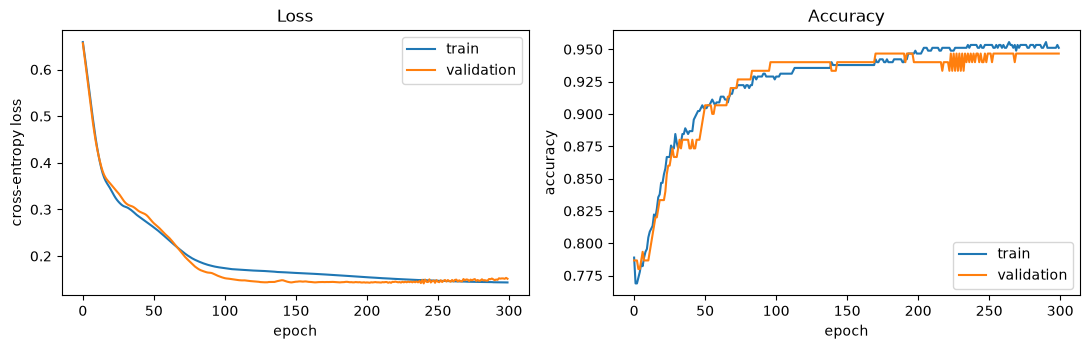

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(hist["train_loss"], label="train"); axes[0].plot(hist["val_loss"], label="validation")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("cross-entropy loss"); axes[0].set_title("Loss"); axes[0].legend()
axes[1].plot(hist["train_acc"], label="train"); axes[1].plot(hist["val_acc"], label="validation")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy"); axes[1].set_title("Accuracy"); axes[1].legend()
plt.tight_layout(); plt.show()

**What just happened?**

Both loss curves fall and then flatten; both accuracy curves rise and then flatten. Crucially, **validation follows training closely**: the network learned a general pattern rather than memorising the training points. This is what a healthy training run looks like.

## 4.4 Seeing the decision boundary

A **decision boundary** is the line where the model switches from predicting class 0 to class 1. We draw it by asking the model about every point on a fine grid and colouring the grid by its answer.

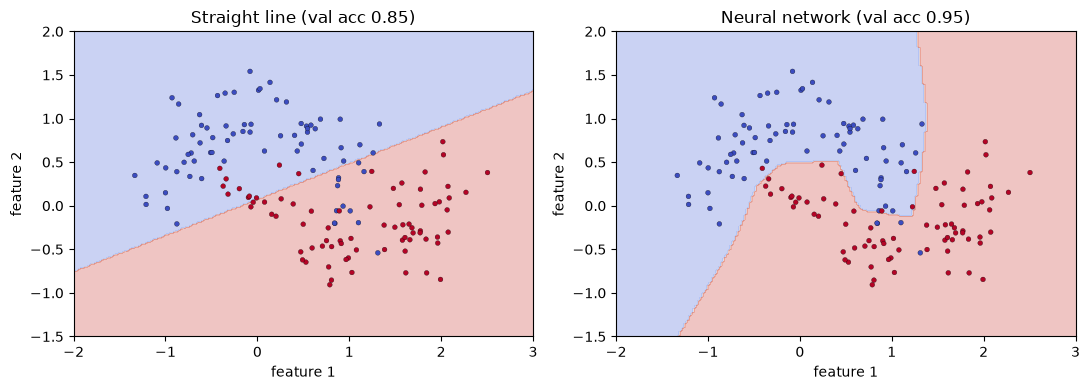

In [27]:
def plot_boundary(model, X, y, ax, title):
    xx, yy = np.meshgrid(np.linspace(-2, 3, 200), np.linspace(-1.5, 2, 200))   # grid of points
    grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)     # (40000, 2)
    model.eval()
    with torch.no_grad():
        pred = model(grid).argmax(dim=1).reshape(xx.shape)                      # class per grid point
    ax.contourf(xx, yy, pred, alpha=0.3, cmap="coolwarm")                       # coloured regions
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=12, edgecolors="k", linewidths=0.2)
    ax.set_xlabel("feature 1"); ax.set_ylabel("feature 2"); ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot_boundary(linear_model, X_va, y_va, axes[0], f"Straight line (val acc {hist_lin['val_acc'][-1]:.2f})")
plot_boundary(model, X_va, y_va, axes[1], f"Neural network (val acc {hist['val_acc'][-1]:.2f})")
plt.tight_layout(); plt.show()

**What just happened?**

Shown on the **validation** points: the straight-line model can only cut the plane in two with a straight line, while the neural network bends its boundary to follow the moons. This bending is exactly what the ReLU hidden layers buy us.

## 4.5 Overfitting: when a model memorises

**Overfitting** = the model learns the training data *too* well, including its noise, and does worse on new data. Recipe to cause it on purpose: a **big** model, **few** training points, **long** training.

We give a network with 2 hidden layers of 256 units (about 67,000 knobs) only **40** training points, and train for 1,000 epochs. A **validation set** of 1,000 other points shows how it does on new data.

In [28]:
class BigNet(nn.Module):
    def __init__(self, hidden=256):
        super().__init__()
        self.net = nn.Sequential(                    # Sequential = layers applied in order
            nn.Linear(2, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, 2))
    def forward(self, x):
        return self.net(x)

Xs, ys = make_moons(n_samples=1040, noise=0.3, random_state=7)        # a fresh set of moons
X_small = torch.tensor(Xs[:40], dtype=torch.float32); y_small = torch.tensor(ys[:40])   # only 40 to learn from
X_val2 = torch.tensor(Xs[40:], dtype=torch.float32);  y_val2 = torch.tensor(ys[40:])    # 1000 to check on

torch.manual_seed(SEED)
big = BigNet()
print("parameters:", sum(p.numel() for p in big.parameters()))
hist_big = train(big, X_small, y_small, X_val2, y_val2, epochs=1000, lr=0.001)
best_epoch = int(np.argmin(hist_big["val_loss"]))
print(f"final  : train acc {hist_big['train_acc'][-1]:.3f} | val acc {hist_big['val_acc'][-1]:.3f} | val loss {hist_big['val_loss'][-1]:.3f}")
print(f"lowest val loss {min(hist_big['val_loss']):.3f} was at epoch {best_epoch}")

parameters: 67074


final  : train acc 1.000 | val acc 0.880 | val loss 0.789
lowest val loss 0.274 was at epoch 62


**What just happened?**

- **Training accuracy reaches 100%**: the big network has memorised all 40 points.
- **Validation accuracy is clearly lower** (high 80s %), and the validation loss at the end is several times *higher* than its lowest value, which happened early in training (around epoch 60). After that point, every extra epoch made the model *more confident on the training points and worse on new ones*.

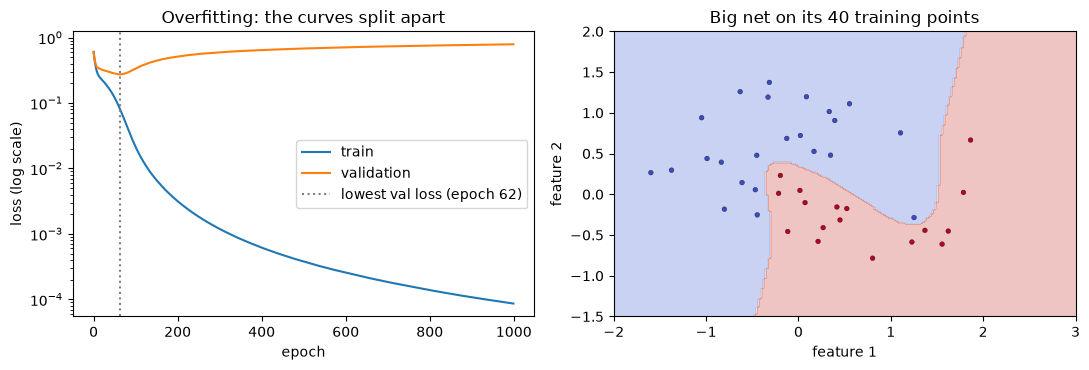

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(hist_big["train_loss"], label="train"); axes[0].plot(hist_big["val_loss"], label="validation")
axes[0].axvline(best_epoch, color="gray", ls=":", label=f"lowest val loss (epoch {best_epoch})")
axes[0].set_yscale("log"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss (log scale)")
axes[0].set_title("Overfitting: the curves split apart"); axes[0].legend()
plot_boundary(big, X_small, y_small, axes[1], "Big net on its 40 training points")
plt.tight_layout(); plt.show()

**What just happened?**

- **Left:** the classic overfitting picture. Training loss keeps diving towards zero while validation loss turns around and climbs. The gap between the curves is the warning sign.
- **Right:** the boundary bends sharply to capture individual awkward training points (for example the blue point sitting among the red ones near feature 1 ≈ 1.2, feature 2 ≈ -0.3): a sign of memorising noise rather than learning the moon shape.

## 4.6 Two fixes: weight decay and early stopping

| Fix | Idea in plain words | How in PyTorch |
|---|---|---|
| **Weight decay** | Penalise large knob values, so the model prefers simpler, smoother boundaries | `torch.optim.AdamW(..., weight_decay=...)` or `Adam(..., weight_decay=...)` |
| **Early stopping** | Watch the validation loss and keep the model from the epoch where it was best | save a copy of the weights whenever validation loss improves |
| (Best fix, if possible) | Get more training data | - |

Below we train the same big network with **weight decay**, and separately implement **early stopping** by remembering the best weights.

> ⚠️ **Common mistake:** choosing the stopping epoch on the validation set and then reporting that same validation score as your final result. It is slightly optimistic, because you *used* those points to make a decision. In real projects you keep a third, untouched **test set** for the final number. Here we use a fresh test set of 1,000 more points.

In [30]:
import copy                                         # to save a snapshot of the weights
Xt, yt = make_moons(n_samples=1000, noise=0.3, random_state=99)         # untouched TEST set
X_test2 = torch.tensor(Xt, dtype=torch.float32); y_test2 = torch.tensor(yt)

torch.manual_seed(SEED)
big_wd = BigNet()                                   # Fix 1: same model + weight decay
hist_wd = train(big_wd, X_small, y_small, X_val2, y_val2, epochs=1000, lr=0.001, weight_decay=0.01)

torch.manual_seed(SEED)
big_es = BigNet()                                   # Fix 2: same model + early stopping
opt = torch.optim.Adam(big_es.parameters(), lr=0.001)
best_val, best_state, patience, waited = float("inf"), None, 50, 0
for epoch in range(1000):
    big_es.train(); loss = loss_fn(big_es(X_small), y_small)
    opt.zero_grad(); loss.backward(); opt.step()
    val_loss, _ = evaluate(big_es, X_val2, y_val2)
    if val_loss < best_val:                         # improvement: remember these weights
        best_val, best_state, waited, stop_epoch = val_loss, copy.deepcopy(big_es.state_dict()), 0, epoch
    else:
        waited += 1
        if waited >= patience: break                # no improvement for 50 epochs: stop
big_es.load_state_dict(best_state)                  # go back to the best snapshot
print(f"early stopping: stopped at epoch {epoch}, kept weights from epoch {stop_epoch}")

early stopping: stopped at epoch 112, kept weights from epoch 62


**What just happened?**

- **Weight decay** trained for all 1,000 epochs, but with a constant pull towards small weights.
- **Early stopping** used a **patience** of 50: if the validation loss has not improved for 50 epochs in a row, stop and restore the best snapshot. It stopped long before epoch 1,000.

Now compare all three on the untouched **test** set:

model                        train acc  test acc  test loss
big net, no fix                  1.000     0.877      0.806
big net + weight decay           0.975     0.897      0.260
big net + early stopping         0.975     0.900      0.275


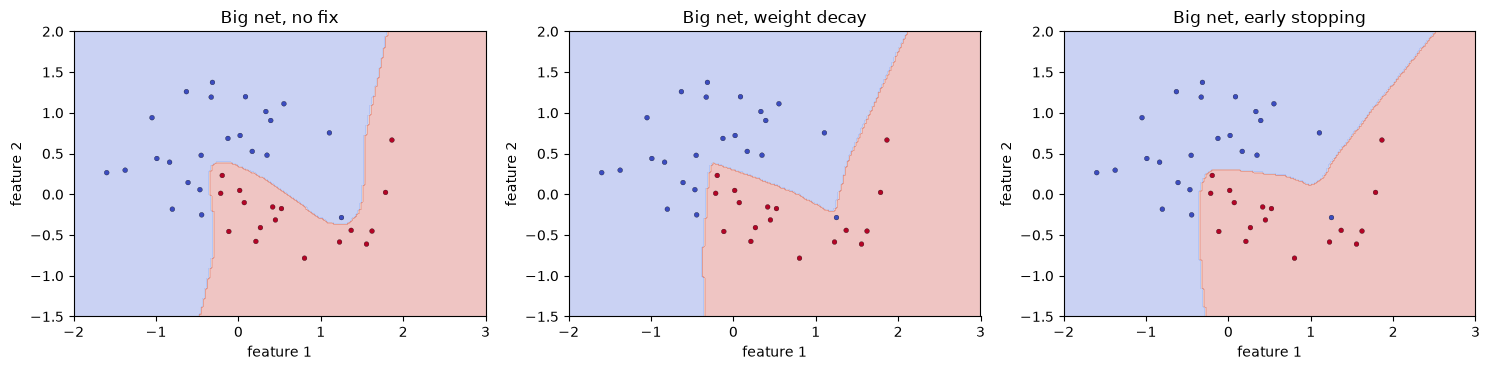

In [31]:
print(f"{'model':<28}{'train acc':>10}{'test acc':>10}{'test loss':>11}")
for name, m in [("big net, no fix", big), ("big net + weight decay", big_wd), ("big net + early stopping", big_es)]:
    tr_loss, tr_acc = evaluate(m, X_small, y_small)
    te_loss, te_acc = evaluate(m, X_test2, y_test2)
    print(f"{name:<28}{tr_acc:>10.3f}{te_acc:>10.3f}{te_loss:>11.3f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (name, m) in zip(axes, [("no fix", big), ("weight decay", big_wd), ("early stopping", big_es)]):
    plot_boundary(m, X_small, y_small, ax, f"Big net, {name}")
plt.tight_layout(); plt.show()

**What just happened?**

- Both fixes give a much **lower test loss** (roughly a third of the un-fixed model's). The un-fixed model is *confidently wrong* on many new points, and cross-entropy punishes confident mistakes heavily.
- Test **accuracy** also improves with both fixes, by a couple of percentage points (from the high 80s to about 90%). With only 40 noisy training points there is a limit to what any model can learn.
- The fixed models no longer get 100% on the training points: they stopped memorising every noisy one.
- In the pictures, the early-stopped boundary is clearly smoother. The weight-decay boundary looks similar in shape to the un-fixed one, yet its test loss is far better. Why? A boundary plot shows only *which* class wins at each point, not *how confident* the model is. Weight decay mostly fixed the over-confidence.

> 💡 **Tip:** watch the *loss* on validation data, not only accuracy. Loss reveals overconfidence long before accuracy drops.

---
# Part 5: Classification details

## 5.1 Logits, softmax and probabilities

Our network outputs raw scores (**logits**), which can be any number, negative or positive. **Softmax** turns a list of scores into probabilities that are all between 0 and 1 and add up to 1:

```
softmax(score_i) = exp(score_i) / sum over all classes of exp(score_j)
```

`exp` (the exponential function) makes everything positive and exaggerates differences: the biggest score gets the biggest share.

In [32]:
logits = torch.tensor([[2.0, 1.0, -1.0]])        # 1 sample, 3 classes
probs = F.softmax(logits, dim=1)                 # dim=1: softmax across the classes
print("logits       :", logits)
print("probabilities:", probs.round(decimals=3))
print("sum of probs :", probs.sum().item())
print("predicted class (argmax of logits):", logits.argmax(dim=1).item(),
      "| argmax of probs:", probs.argmax(dim=1).item())

logits       : tensor([[ 2.,  1., -1.]])
probabilities: tensor([[0.7050, 0.2590, 0.0350]])
sum of probs : 1.0000001192092896
predicted class (argmax of logits): 0 | argmax of probs: 0


**What just happened?**

Scores 2, 1, -1 became probabilities of about 0.705, 0.259 and 0.035, summing to 1 (the printed `1.0000001` is normal floating-point rounding: computers store decimals with limited precision). Softmax never changes *which* class is biggest, so for picking the predicted class you can simply use `argmax` on the logits.

## 5.2 `CrossEntropyLoss` expects raw logits

**Cross-entropy** measures how much probability the model gave to the *correct* class: `loss = -log(probability of the true class)`. Probability 1 → loss 0; probability near 0 → huge loss.

> ⚠️ **Common mistake: applying softmax before `nn.CrossEntropyLoss`.**
> `nn.CrossEntropyLoss` *already* applies softmax internally (in a numerically safe way). If you add your own softmax at the end of the model, softmax is applied **twice**. Nothing crashes, but the loss is wrong and learning becomes slow. Your model's `forward` should return **raw logits**.

In [33]:
target = torch.tensor([0])                                   # the true class is 0
ce = nn.CrossEntropyLoss()

right = ce(logits, target)                                   # correct: raw logits
by_hand = -torch.log(F.softmax(logits, dim=1)[0, 0])         # -log(prob of true class)
wrong = ce(F.softmax(logits, dim=1), target)                 # WRONG: softmax applied twice
print(f"CrossEntropyLoss(logits)          = {right.item():.4f}")
print(f"-log(softmax prob of true class)  = {by_hand.item():.4f}   (same thing)")
print(f"CrossEntropyLoss(softmax(logits)) = {wrong.item():.4f}   <- wrong value")

CrossEntropyLoss(logits)          = 0.3490
-log(softmax prob of true class)  = 0.3490   (same thing)
CrossEntropyLoss(softmax(logits)) = 0.7663   <- wrong value


**What just happened?**

The correct loss (about 0.35) equals `-log(0.705)`, confirming what `CrossEntropyLoss` does. Feeding it probabilities instead gives a different, wrong number (about 0.77). Worse, the double softmax squashes the outputs into a narrow range, so the gradients become small and training crawls.

For the targets there is one more rule: **class labels must be integers (`torch.long`) of shape `(batch,)`**, not floats. Here is the error you get otherwise:

In [34]:
bad_target = torch.tensor([0.0])                    # float label: wrong dtype
try:
    ce(logits, bad_target)
except RuntimeError as err:
    print("RuntimeError:", err)
print("fix:", ce(logits, bad_target.long()).item())  # convert labels with .long()

RuntimeError: expected target dtype to be Long or Byte, but got Float
fix: 0.349012166261673


**What just happened?**

The message says `expected target dtype to be Long or Byte, but got Float`: the loss wants integer class numbers (`Long` = int64) and we gave it a float. Labels are *category numbers*, not quantities, so they must be integers. `.long()` fixes it.

> 💡 **Tip:** for **binary** problems with a single output score per sample, use `nn.BCEWithLogitsLoss` (float targets 0.0 / 1.0, also expects raw logits). For 2 or more classes with one score per class, use `nn.CrossEntropyLoss` as we did.

## 5.3 `model.train()` vs `model.eval()`

Some layers behave differently while learning and while predicting. The most common one is **Dropout**: during training it randomly switches off a fraction of the units each step (so the network cannot rely on any single unit, which reduces overfitting). During prediction you want every unit and a deterministic answer.

- `model.train()` → training behaviour (dropout active)
- `model.eval()` → prediction behaviour (dropout off)

`model.eval()` does **not** turn off gradient tracking; that is `torch.no_grad()`'s job. For prediction you normally use both.

In [35]:
torch.manual_seed(SEED)
drop_model = nn.Sequential(nn.Linear(2, 32), nn.ReLU(), nn.Dropout(p=0.5), nn.Linear(32, 2))
point = torch.tensor([[0.5, 0.2]])                     # one input point

drop_model.train()                                     # dropout ON
with torch.no_grad():
    print("train mode, 3 calls:", [drop_model(point)[0, 0].item() for _ in range(3)])
drop_model.eval()                                      # dropout OFF
with torch.no_grad():
    print("eval  mode, 3 calls:", [drop_model(point)[0, 0].item() for _ in range(3)])

train mode, 3 calls: [-0.0544467568397522, 0.2520771920681, -0.05611167848110199]
eval  mode, 3 calls: [-0.04158686101436615, -0.04158686101436615, -0.04158686101436615]


**What just happened?**

In train mode the same input gives **three different outputs** because a different random half of the units is dropped each time. In eval mode the output is identical every time.

> ⚠️ **Common mistake:** forgetting `model.eval()` before measuring validation accuracy or making predictions. Your numbers become noisy and lower than they should be. Forgetting `model.train()` afterwards silently disables dropout for the rest of training. (Our `train`/`evaluate` helpers in Part 4 switch modes for exactly this reason.)

## 5.4 Saving and loading a model

A model's learned knobs live in its **`state_dict`**: a dictionary from layer names to weight tensors. The recommended way to save is to save the `state_dict` (not the whole Python object), then rebuild the model class and load the weights into it.

We save into a temporary folder that we delete afterwards.

In [36]:
tmp_dir = tempfile.mkdtemp()                              # a throwaway folder
path = os.path.join(tmp_dir, "moonnet.pt")

print("state_dict keys:", list(model.state_dict().keys()))
torch.save(model.state_dict(), path)                      # save only the weights
print(f"saved {os.path.getsize(path):,} bytes")

restored = MoonNet()                                      # 1. rebuild the same architecture
restored.load_state_dict(torch.load(path, weights_only=True))   # 2. load the weights
restored.eval()                                           # 3. prediction mode
with torch.no_grad():
    same = torch.equal(model(X_va), restored(X_va))       # identical outputs?
print("restored model gives identical predictions:", same)
print("restored val accuracy:", round(evaluate(restored, X_va, y_va)[1], 3))

shutil.rmtree(tmp_dir)                                    # clean up

state_dict keys: ['layer1.weight', 'layer1.bias', 'layer2.weight', 'layer2.bias', 'out.weight', 'out.bias']
saved 4,117 bytes
restored model gives identical predictions: True
restored val accuracy: 0.947


**What just happened?**

- The `state_dict` has a weight and a bias for each of the three layers.
- The saved file is tiny (a few kilobytes: 354 numbers plus some labels).
- A fresh `MoonNet()` with the loaded weights gives *exactly* the same predictions and the same validation accuracy as the trained one.
- `weights_only=True` tells `torch.load` to load only tensors, not arbitrary Python objects, which is safer for files you did not create yourself.

---
# Part 6: Debugging a training loop

When training does not work, go down this checklist. Most problems are one of these:

| Symptom | Likely cause | What to try |
|---|---|---|
| Loss does not go down at all | learning rate far too small; forgot `optimizer.step()`; optimizer built on the wrong model's parameters | print the loss each epoch; check `optimizer.step()` is called; try a 10x bigger `lr` |
| Loss jumps around or explodes to `inf` / `nan` | **learning rate too high**; inputs not scaled (values in the thousands) | lower `lr` 10x; standardise inputs (mean 0, std 1) |
| Loss is `nan` from the start | `nan` in the data; `log(0)`; division by zero | `torch.isnan(X).any()`; use built-in losses instead of hand-made logs |
| Loss decreases strangely or erratically | **forgot `optimizer.zero_grad()`** | add it before `loss.backward()` |
| Error mentioning shapes | layer sizes don't match the data | print `.shape` of every tensor in `forward` |
| No error, but results are poor / warning about "target size" | **silent shape broadcasting**, e.g. prediction `(N, 1)` vs target `(N,)` | make shapes identical (`.squeeze(1)` or `.unsqueeze(1)`) |
| Training accuracy high, validation low | overfitting | more data, weight decay, early stopping, smaller model, dropout |
| Train and validation both poor | underfitting / model too simple / bug | bigger model, train longer; first make sure it can overfit a tiny batch |

> 💡 **Tip, the single best debugging trick:** take **one small batch** (say 8 samples) and train on only that. A correct model and loop should drive the loss to almost zero. If it can't, there is a bug in the code, not a data problem.

Let's demonstrate the most common ones.

## 6.1 Learning rate too high → divergence

We rerun the manual linear regression from 3a with three learning rates.

lr=0.01  loss after 30 steps: 3.32


lr=0.5   loss after 30 steps: 0.0597


lr=1.5   loss after 30 steps: 1.51e+18


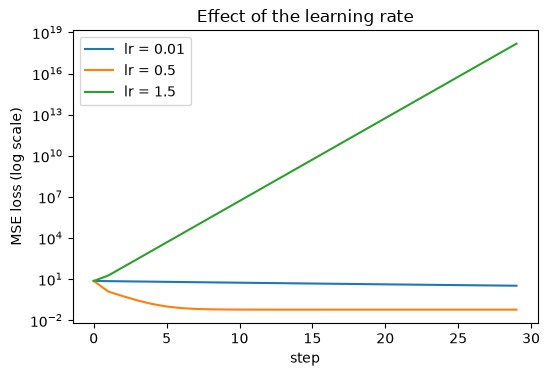

In [37]:
def fit_line(lr, steps=30, zero_grad=True):
    torch.manual_seed(SEED)
    w = torch.zeros(1, requires_grad=True); b = torch.zeros(1, requires_grad=True)
    losses = []
    for _ in range(steps):
        loss = ((X * w + b - Y) ** 2).mean()           # forward + MSE
        loss.backward()
        with torch.no_grad():
            w -= lr * w.grad; b -= lr * b.grad          # update
        if zero_grad:                                  # the step we will "forget" in 6.2
            w.grad.zero_(); b.grad.zero_()
        losses.append(loss.item())
    return losses

plt.figure(figsize=(6, 3.8))
for lr in [0.01, 0.5, 1.5]:
    curve = fit_line(lr)
    print(f"lr={lr:<5} loss after 30 steps: {curve[-1]:.3g}")
    plt.plot(curve, label=f"lr = {lr}")
plt.yscale("log"); plt.xlabel("step"); plt.ylabel("MSE loss (log scale)")
plt.title("Effect of the learning rate"); plt.legend(); plt.show()

**What just happened?**

- `lr = 0.01` is **too small**: the loss is still high after 30 steps (it would get there eventually, very slowly).
- `lr = 0.5` is **good**: the loss drops to the noise floor in a few steps.
- `lr = 1.5` is **too high**: every step overshoots the bottom of the valley and lands *higher* on the other side, so the loss grows exponentially. Left running, it would become `inf` and then `nan`.

The fix is almost always to lower the learning rate by a factor of 10 and try again.

## 6.2 Forgetting `zero_grad`

with zero_grad   : final loss 0.0603
without zero_grad: final loss 2.9528


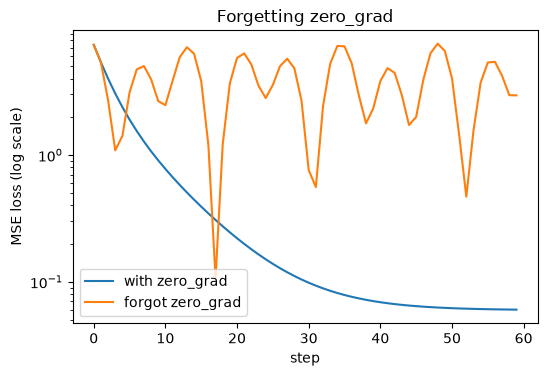

In [38]:
good = fit_line(lr=0.1, steps=60, zero_grad=True)
forgot = fit_line(lr=0.1, steps=60, zero_grad=False)     # gradients pile up step after step
print(f"with zero_grad   : final loss {good[-1]:.4f}")
print(f"without zero_grad: final loss {forgot[-1]:.4f}")

plt.figure(figsize=(6, 3.8))
plt.plot(good, label="with zero_grad"); plt.plot(forgot, label="forgot zero_grad")
plt.yscale("log"); plt.xlabel("step"); plt.ylabel("MSE loss (log scale)")
plt.title("Forgetting zero_grad"); plt.legend(); plt.show()

**What just happened?**

Without `zero_grad` each update uses the *sum of all past gradients*. The knobs build up momentum like a ball that can't brake, overshoot, swing back and forth, and the loss bounces instead of settling smoothly. No error message appears: this bug is **silent**, which is why it is on every checklist.

## 6.3 The silent shape bug: `(N, 1)` vs `(N,)`

This one produces no error, only a warning that is easy to miss, and a wrong loss.

In [39]:
pred = torch.tensor([[1.], [2.], [3.], [4.]])  # PERFECT predictions, but shape (4, 1)
target = torch.tensor([1., 2., 3., 4.])        # target: shape (4,)  <- different!
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    bad = nn.MSELoss()(pred, target)           # broadcasts to (4, 4): every pred vs every target
print("warning:", str(caught[0].message)[:110], "...")
print("(pred - target) shape:", tuple((pred - target).shape))
good = nn.MSELoss()(pred.squeeze(1), target)   # make both (4,)
print(f"buggy loss = {bad.item():.2f}   correct loss = {good.item():.2f}")

(pred - target) shape: (4, 4)
buggy loss = 2.50   correct loss = 0.00


**What just happened?**

The predictions are *perfect*, so the true loss is 0. But broadcasting (Section 1.5) turned `(4, 1) - (4,)` into a `(4, 4)` grid that compares every prediction with *every* target, and the buggy loss comes out as 2.50. A model trained on that loss would be pushed towards predicting the average of all targets for everything. PyTorch only *warns*; the code runs. The rule: **make prediction and target shapes identical** (here with `.squeeze(1)`), and treat that warning as an error.

## 6.4 Catching NaNs early

A **NaN** ("not a number") appears after impossible math such as `0/0` or `log` of a negative number, and then spreads to everything it touches. Check for it early instead of discovering it 100 epochs later.

In [40]:
data = torch.tensor([1.0, 2.0, float("nan"), 4.0])      # one corrupted value
print("any NaN in data?", torch.isnan(data).any().item())
print("mean of data   :", data.mean().item())            # NaN spreads to the result

def check_finite(name, t):
    if not torch.isfinite(t).all():                      # isfinite: not NaN and not +-inf
        raise ValueError(f"{name} contains NaN or inf!")

try:
    check_finite("loss", data.mean())
except ValueError as err:
    print("caught:", err)

any NaN in data? True
mean of data   : nan
caught: loss contains NaN or inf!


**What just happened?**

One bad value made the whole mean `nan`. A one-line check like `check_finite` inside your loop stops training at the first bad step and tells you where the problem is, instead of letting you train a broken model for an hour.

In [41]:
print(f"Whole notebook ran in {time.time() - NOTEBOOK_START:.1f} seconds on {device}.")

Whole notebook ran in 60.7 seconds on cpu.


---
# Recap

- A **tensor** is a NumPy-like grid of numbers that can also live on a GPU and track gradients. Always know its **shape** and **dtype** (`float32` for inputs and weights, `long` for class labels).
- **Broadcasting** stretches size-1 dimensions; it is powerful and also the source of silent bugs. **Matrix multiplication** needs matching inner sizes: `(n, k) @ (k, m) → (n, m)`.
- **Autograd**: mark tensors with `requires_grad=True`, compute a single loss, call `.backward()`, read `.grad`. We checked it against hand calculations.
- Gradients **accumulate**, so clear them every step with `optimizer.zero_grad()`. Use `torch.no_grad()` for inference and manual updates.
- The **5-step loop**: forward → loss → `zero_grad` → `backward` → `step`. `nn.Linear`, `nn.MSELoss`, `optim.SGD` / `Adam` and `DataLoader` are conveniences around it.
- Judge models on **validation** data; keep a separate **test** set for the final number. Overfitting shows up as a growing gap between training and validation loss; **weight decay** and **early stopping** reduce it.
- `nn.CrossEntropyLoss` wants **raw logits** and **integer labels**. Use `model.eval()` + `torch.no_grad()` for predictions. Save the **`state_dict`**.
- Debugging: check the learning rate, `zero_grad`, shapes and NaNs, and try to overfit one small batch.

# Exercises

**1. (Easy) Shapes.** Create a tensor `t = torch.arange(24)`. Reshape it to `(2, 3, 4)`, then compute the sum over the last dimension. What is the shape of the result?

<details><summary>Show solution</summary>

```python
t = torch.arange(24).reshape(2, 3, 4)
s = t.sum(dim=-1)        # dim=-1 means "the last dimension"
print(s.shape)           # torch.Size([2, 3]): the last dimension is summed away
```
</details>

**2. (Easy) Autograd check.** For `y = 4*x**3 - x` at `x = 1.5`, compute the slope with autograd and compare it with the hand rule `12*x**2 - 1`.

<details><summary>Show solution</summary>

```python
x = torch.tensor(1.5, requires_grad=True)
y = 4 * x**3 - x
y.backward()
print(x.grad.item(), 12 * 1.5**2 - 1)   # both 26.0
```
</details>

**3. (Medium) Learning rate search.** Using `fit_line` from Section 6.1, try learning rates `[0.05, 0.1, 0.5, 0.9, 1.1]` and print the final loss for each. Roughly where does training start to diverge?

<details><summary>Show solution</summary>

```python
for lr in [0.05, 0.1, 0.5, 0.9, 1.1]:
    print(lr, fit_line(lr)[-1])
```
Small rates converge slowly (0.05 is still well above the noise floor after 30 steps), 0.5 and 0.9 converge fast, and 1.1 already diverges: the tipping point lies between 0.9 and 1.1 for this data (it depends on the spread of the inputs).
</details>

**4. (Medium) Width experiment.** Train `MoonNet(hidden=h)` for `h` in `[2, 4, 16, 64]` with the `train` function from Part 4 and print the final validation accuracy. What happens with very few hidden units?

<details><summary>Show solution</summary>

```python
for h in [2, 4, 16, 64]:
    torch.manual_seed(SEED)
    m = MoonNet(hidden=h)
    hst = train(m, X_tr, y_tr, X_va, y_va)
    print(h, round(hst["val_acc"][-1], 3))
```
With 2 hidden units the network can bend its boundary only a little and scores about the same as the straight-line model (mid-80s %). With 4 units it already reaches the low-to-mid 90s, and more units do not help further: the noise in the data is now the limit.
</details>

**5. (Harder) Mini-batch moons.** Rewrite the Part 4 training so it uses a `DataLoader` with `batch_size=32` and `shuffle=True` (like Section 3c), training `MoonNet` for 50 epochs. Print the validation accuracy after every 10 epochs.

<details><summary>Show solution</summary>

```python
torch.manual_seed(SEED)
m = MoonNet()
opt = torch.optim.Adam(m.parameters(), lr=0.01)
loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=32, shuffle=True)
for epoch in range(1, 51):
    m.train()
    for xb, yb in loader:
        loss = loss_fn(m(xb), yb)
        opt.zero_grad(); loss.backward(); opt.step()
    if epoch % 10 == 0:
        print(epoch, round(evaluate(m, X_va, y_va)[1], 3))
```
</details>

# Where to go next

- [01_neural_network_fundamentals.ipynb](01_neural_network_fundamentals.ipynb): the math behind what you just did (neurons, activation functions, backpropagation by hand).
- [02_optimizers.ipynb](02_optimizers.ipynb): how SGD, momentum and Adam differ.
- [../06_Computer_Vision/00_start_here_images_and_your_first_cnn.ipynb](../06_Computer_Vision/00_start_here_images_and_your_first_cnn.ipynb): images, convolutions and training your first CNN, written in the same beginner style.
- [03_cnn.ipynb](03_cnn.ipynb) and [04_rnn_lstm_gru.ipynb](04_rnn_lstm_gru.ipynb): network types for images and sequences.
- [16_industry_pytorch_training_pipeline.ipynb](16_industry_pytorch_training_pipeline.ipynb): the professional version of this notebook's training loop (configs, checkpoints, early stopping, logging, reproducibility).
- [notes/05_Deep_Learning.md](notes/05_Deep_Learning.md): the summary notes for this module.